In [1]:
%pip install pandas numpy matplotlib scikit-learn streamlit

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
np.random.seed(42)

n = 200

data = pd.DataFrame({
    "hour": np.arange(n),
    "cpu_usage": np.random.uniform(10, 90, n),
    "memory_usage": np.random.uniform(20, 85, n),
    "request_count": np.random.randint(100, 2000, n)
})

# Generate a target CPU usage for prediction
data["future_cpu"] = (
    0.45 * data["cpu_usage"]
    + 0.20 * data["memory_usage"]
    + 0.015 * (data["request_count"] / 10)
    + np.random.normal(0, 5, n)
).clip(0, 100)

data.head()

,hour,cpu_usage,memory_usage,request_count,future_cpu
0,0,39.963210,61.732057,972,28.556358
1,1,86.057145,25.469098,1921,44.683260
2,2,68.559515,30.505866,1396,47.470380
3,3,57.892679,78.406022,161,33.322833
4,4,22.481491,59.417889,695,23.752999


In [4]:
X = data[["cpu_usage", "memory_usage", "request_count"]]
y = data["future_cpu"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 160
Testing records: 40


In [5]:
X = data[["cpu_usage", "memory_usage", "request_count"]]
y = data["future_cpu"]

print("Total records:", len(data))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Total records: 200
Training records: 160
Testing records: 40


In [6]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    )
}

results = {}
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results[name] = {
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    }

    trained_models[name] = model

print("Both models trained successfully!")

Both models trained successfully!


                     MAE   RMSE  R2 Score
Linear Regression  4.917  5.812     0.824
Random Forest      5.022  5.890     0.819


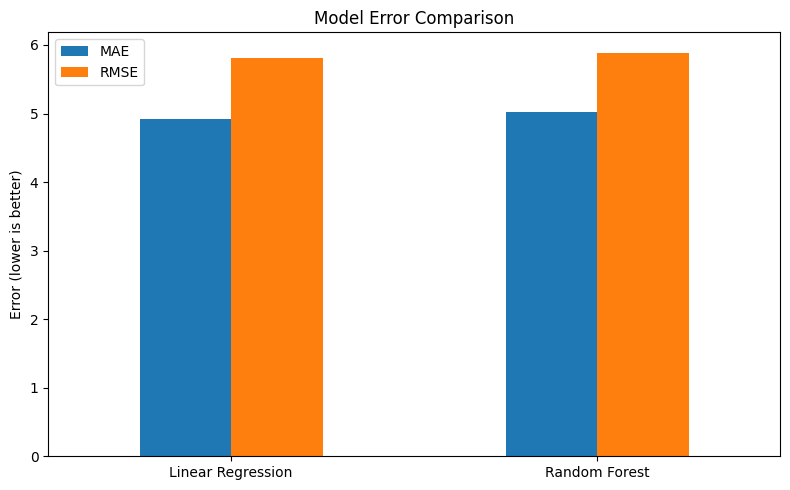

In [7]:
results_df = pd.DataFrame(results).T

print(results_df.round(3))

results_df[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(8, 5),
    title="Model Error Comparison"
)

plt.ylabel("Error (lower is better)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [8]:
new_resource = pd.DataFrame({
    "cpu_usage": [75],
    "memory_usage": [70],
    "request_count": [1500]
})

for name, model in trained_models.items():
    prediction = model.predict(new_resource)[0]

    print(f"\nModel: {name}")
    print(f"Predicted future CPU usage: {prediction:.2f}%")

    if prediction >= 80:
        print("Recommendation: Review cloud resource capacity.")
    else:
        print("Recommendation: No high CPU warning.")


Model: Linear Regression
Predicted future CPU usage: 49.44%
Recommendation: No high CPU warning.

Model: Random Forest
Predicted future CPU usage: 47.93%
Recommendation: No high CPU warning.


In [9]:
data.to_csv("cloud_resource_data.csv", index=False)
results_df.to_csv("model_comparison.csv")

print("Dataset saved successfully!")
print("Model comparison saved successfully!")

Dataset saved successfully!
Model comparison saved successfully!
